# Artemis and Image Safari — crop imagery datasets (data descriptor reproduction)

**Paper:** Mutuvi S. et al. (2026). *Artemis and Image Safari - Crop Imagery Datasets Spanning Globally Critical Crop Species.* agriRxiv preprint, DOI [10.31220/agriRxiv.2026.00491](https://doi.org/10.31220/agrirxiv.2026.00491).

**Data:** [Registry of Open Data on AWS](https://registry.opendata.aws/artemis-image-safari) — public bucket `s3://alliance-artemis-imagesafari/` (us-west-2), CC BY-SA 4.0.
**Author documentation/tutorial:** [CIAT-Artemis/imagesafari-artemis-crop-images](https://github.com/CIAT-Artemis/imagesafari-artemis-crop-images) @ commit `05868dd7071f8d366ab64373ea87afe24b8150e4`.

**Scope (partial demonstration of a data descriptor):** This notebook reproduces the authors' introductory tutorial on the public S3 bucket — browse crop prefixes, display one Image Safari image, and plot the published crop distribution — and then exercises the Artemis structured-phenotyping side: it loads the smallest published Artemis annotation set (common-bean *instance_segmentation: flower*), verifies its image/annotation counts against the authors' documentation, renders **reference annotations** (not model predictions) over one deterministically chosen annotated image, and joins the annotated images to Artemis field metadata.

This is a **one-example dataset walkthrough**, not a verification of dataset-level statistics: the collection has ~7.5 million images and nothing here re-measures it exhaustively. The paper's full text was not retrievable (publisher 403); every step below is grounded in the authors' own tutorial, docs (`docs/artemis.md`), and the public bucket.

**日本語の概要:** このノートブックは、データ記述論文（agriRxiv preprint, 2026）が公開する Artemis / Image Safari 作物画像データセットの著者チュートリアルを再現します。匿名アクセス可能な公開 S3 バケットから作物プレフィックスの閲覧・画像 1 枚の表示・作物別分布グラフを行い、さらに Artemis の最小アノテーションセット（common-bean / instance_segmentation: flower）の COCO JSON を読み込んで、著者ドキュメント記載の枚数・アノテーション数と照合します。最後に、決定的に選んだ 1 枚のアノテーション付き画像に**参照アノテーション**（モデル予測ではありません）を重ねて描画し、Artemis のメタデータとの結合を確認します。

## Runtime selection and how to run

**Select a CPU runtime.** No GPU and no trained model are involved: the heaviest operations are one S3 JSON download (a few tens of MB), a handful of JPEGs, and a small pandas join. A GPU runtime works identically but adds nothing.

**Runtime: Runtime → Change runtime type → CPU.** Then *Runtime → Run all*. Expected wall time ≈ 5–10 minutes; expected downloads ≈ 60 MB (one ~20 MB COCO JSON + one ~37 MB Parquet metadata file + a few images).

**制限:** GPU は不要です（モデル推論を行いません）。所要時間の目安は 5〜10 分、ダウンロードは合計約 60 MB です。

### Install dependencies

`boto3`/`botocore` (S3 access), `pandas`/`pyarrow` (Artemis metadata is Parquet/CSV), and `pillow`/`matplotlib` (image decode and plots). All are standard wheels already available in Colab; the pinned install is quick and makes the notebook self-contained.

**Expected result:** a quiet successful install; versions printed.

In [ ]:
%pip install -q boto3 pandas pyarrow pillow matplotlib
import boto3, botocore, pandas, pyarrow, PIL, matplotlib
print("boto3", boto3.__version__, "| botocore", botocore.__version__,
      "| pandas", pandas.__version__, "| pyarrow", pyarrow.__version__,
      "| pillow", PIL.__version__, "| matplotlib", matplotlib.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━ 6.8/16.1 MB 98.1 MB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 75.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.3/90.3 kB 6.3 MB/s eta 0:00:00


boto3 1.43.118 | botocore 1.43.118 | pandas 2.2.3 | pyarrow 23.0.1 | pillow 11.3.0 | matplotlib 3.10.0


## Libraries and public S3 connection

The following cell is **copied verbatim from the authors' tutorial** (pinned commit `05868dd`, file `get-to-know-a-dataset-imagesafari_artemis.ipynb`): it creates an anonymous S3 client for the collection bucket `alliance-artemis-imagesafari` in `us-west-2`. No AWS credentials are needed.

**Expected result:** no output; the `s3` client is ready.

**Expected result (JA):** 出力なし。匿名 S3 クライアント `s3` の準備が完了します。

In [ ]:
from io import BytesIO

import boto3
import matplotlib.pyplot as plt
from botocore import UNSIGNED
from botocore.config import Config
from PIL import Image

BUCKET = "alliance-artemis-imagesafari"
REGION = "us-west-2"

s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED),
)

## Browse the crop prefixes

Again **verbatim from the authors' tutorial**: list the top-level `ImageSafari/` crop prefixes anonymously. This is a small listing request (no image bytes).

**Expected result:** a list of crop directory prefixes (18 crops per the documentation).

**Expected result (JA):** 18 作物分のプレフィックス一覧が返ります。

In [ ]:
response = s3.list_objects_v2(Bucket=BUCKET, Prefix="ImageSafari/", Delimiter="/")
crop_prefixes = [item["Prefix"] for item in response.get("CommonPrefixes", [])]
crop_prefixes

['ImageSafari/african-yam/',
 'ImageSafari/banana/',
 'ImageSafari/cassava/',
 'ImageSafari/chickpea/',
 'ImageSafari/common-bean/',
 'ImageSafari/cowpea/',
 'ImageSafari/finger-millet/',
 'ImageSafari/groundnut/',
 'ImageSafari/lentil/',
 'ImageSafari/maize/',
 'ImageSafari/pearl-millet/',
 'ImageSafari/pigeon-pea/',
 'ImageSafari/potato/',
 'ImageSafari/rice/',
 'ImageSafari/sorghum/',
 'ImageSafari/soybean/',
 'ImageSafari/sweet-potato/',
 'ImageSafari/wheat/',
 'ImageSafari/yam/']

## Download and display one image

**Verbatim from the authors' tutorial:** find the first supported image under the `potato/` prefix, download it into memory, and display it. This is the minimal input preview before any analysis; the key is chosen by the bucket's own (lexicographic) listing order, not hand-picked.

**Expected result:** one field photograph of potato rendered below, titled with its S3 key.

**Expected result (JA):** `potato/` 配下の最初の対応画像 1 枚が S3 キー付きで表示されます。

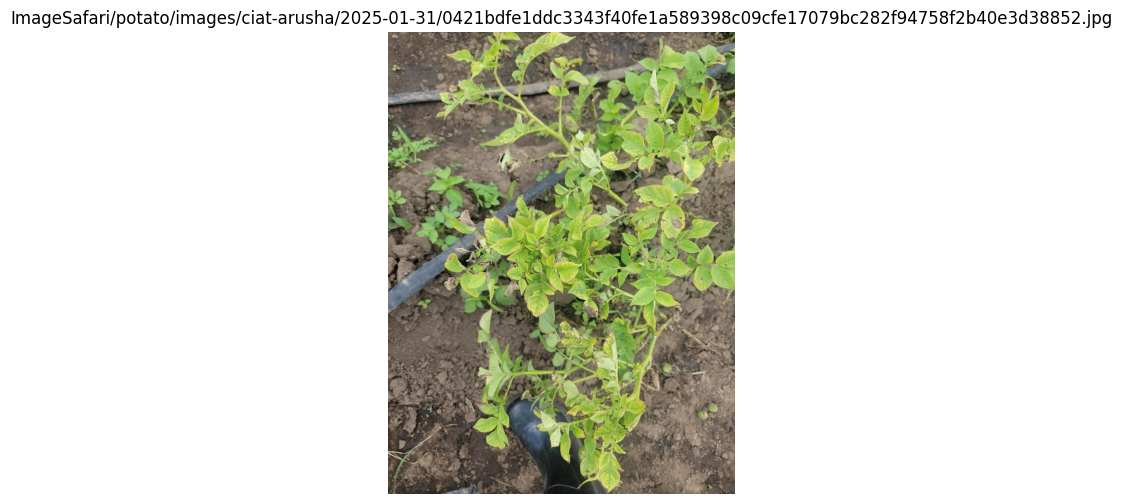

In [ ]:
extensions = (".jpg", ".jpeg", ".png", ".webp")
page = s3.list_objects_v2(Bucket=BUCKET, Prefix="ImageSafari/potato/images/", MaxKeys=1000)
image_key = next(
    item["Key"]
    for item in page.get("Contents", [])
    if item["Key"].lower().endswith(extensions)
)

body = s3.get_object(Bucket=BUCKET, Key=image_key)["Body"].read()
image = Image.open(BytesIO(body)).convert("RGB")

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.title(image_key)
plt.axis("off")
plt.show()

## What does the collection distribution look like?

**Verbatim from the authors' tutorial.** The chart below uses the crop counts that the authors verified from their cleaned dataset report (hard-coded in the author notebook; 18 crops, 6,081,555 Image Safari images total). We do not recompute these counts from the bucket.

**Expected result:** a horizontal bar chart, long-tailed: potato largest, soybean and cassava smallest.

**Expected result (JA):** 著者が検証済みとする作物別画像数（計 6,081,555 枚）の横棒グラフが表示されます。

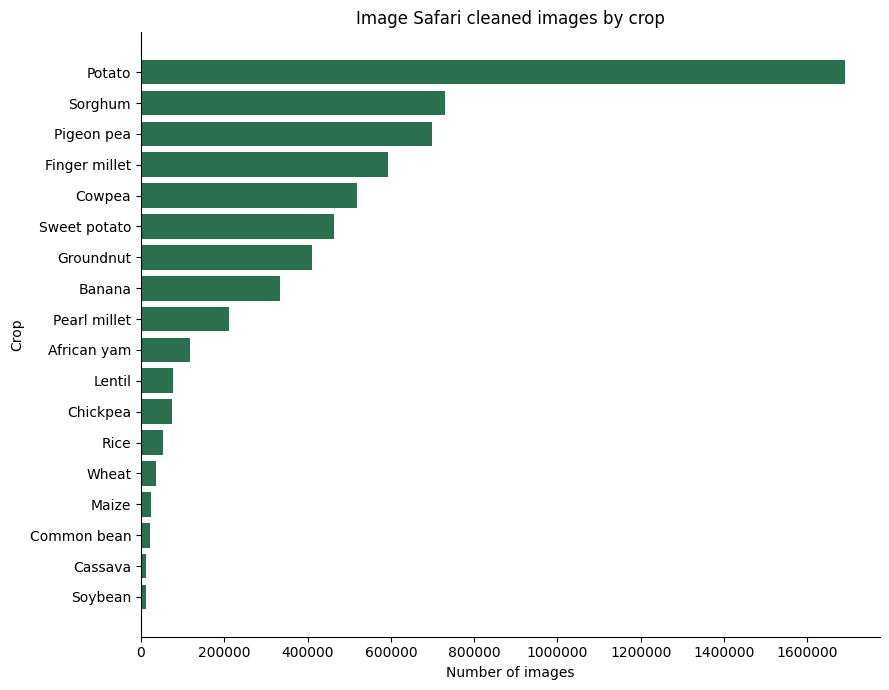

Total images: 6,081,555


In [ ]:
crop_counts = {
    "Potato": 1689917,
    "Sorghum": 730682,
    "Pigeon pea": 698011,
    "Finger millet": 593461,
    "Cowpea": 519759,
    "Sweet potato": 462894,
    "Groundnut": 411948,
    "Banana": 334732,
    "Pearl millet": 211390,
    "African yam": 117494,
    "Lentil": 78218,
    "Chickpea": 73856,
    "Rice": 53170,
    "Wheat": 37023,
    "Maize": 23348,
    "Common bean": 22295,
    "Cassava": 12120,
    "Soybean": 11237,
}

names = list(reversed(crop_counts.keys()))
counts = [crop_counts[name] for name in names]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(names, counts, color="#2b6f4e")
ax.set_xlabel("Number of images")
ax.set_ylabel("Crop")
ax.set_title("Image Safari cleaned images by crop")
ax.spines[["top", "right"]].set_visible(False)
ax.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

print(f"Total images: {sum(crop_counts.values()):,}")

**One answered question (from the authors' tutorial):** how imbalanced is the crop distribution? The next author cell computes the largest crop's share.

**Expected result:** Potato ≈ 27.8% of the collection.

**Expected result (JA):** 最大クラス Potato の割合（約 27.8%）が出力されます。

In [ ]:
total = sum(crop_counts.values())
largest_crop = max(crop_counts, key=crop_counts.get)
largest_share = 100 * crop_counts[largest_crop] / total

print(f"Largest crop: {largest_crop}")
print(f"Images: {crop_counts[largest_crop]:,}")
print(f"Share: {largest_share:.1f}%")

Largest crop: Potato
Images: 1,689,917
Share: 27.8%


## Artemis: load one published annotation set and verify it

The first half reproduced the Image Safari part of the author tutorial. The remainder exercises the **Artemis structured phenotyping** side, following the paper's minimal reproduction plan.

Per `docs/artemis.md` (pinned commit), the common-bean published sets are: instance_segmentation `flower` (**854 images / 14,434 annotations**) and `pod`, object_detection `plant_stand` and `pod`. We pick the **flower** set — the smallest — and verify its actual counts against the documented values.

**Note on layout:** the pinned documentation describes `annotations/standard/<task>/<set>/`, but in the current bucket the common-bean sets live under `annotations/bush-bean/<task>/<set>/` and `annotations/standard/` is empty — an inventory discrepancy between docs and data that we handle by discovering the JSON keys defensively instead of hard-coding the documented path. Set names are also prefixed (`bushbean_flower` for the documented `flower` set).

**Expected result:** the four common-bean annotation JSON keys with their byte sizes.

**Expected result (JA):** common-bean のアノテーション JSON キー（サイズ付き）を一覧します。なお、バケットの実際の配置はドキュメントの `annotations/standard/...` とは異なるため、防御的に探索します。

In [ ]:
anno_root = "Artemis/common-bean/annotations/"
json_keys, token = [], None
while True:
    kw = dict(Bucket=BUCKET, Prefix=anno_root, MaxKeys=1000)
    if token:
        kw["ContinuationToken"] = token
    r = s3.list_objects_v2(**kw)
    json_keys += [(i["Key"], i["Size"]) for i in r.get("Contents", [])
                  if i["Key"].lower().endswith(".json")]
    token = r.get("NextContinuationToken")
    if not token:
        break
json_keys.sort()
for k, s in json_keys:
    print(f"{s:>12,}  {k}")
json_key = next(k for k, s in json_keys
                if "instance_segmentation" in k and "flower" in k)
set_prefix = json_key.rsplit("/", 1)[0] + "/"
print("chosen set:", json_key)

  20,399,797  Artemis/common-bean/annotations/bush-bean/instance_segmentation/bushbean_flower/bushbean_flower_all.json
   8,287,533  Artemis/common-bean/annotations/bush-bean/instance_segmentation/bushbean_pod/bushbean_pod_all.json
   5,669,469  Artemis/common-bean/annotations/bush-bean/object_detection/bushbean_plant_stand/bushbean_plant_stand_all.json
   6,793,896  Artemis/common-bean/annotations/bush-bean/object_detection/bushbean_pod/bushbean_pod_all.json
chosen set: Artemis/common-bean/annotations/bush-bean/instance_segmentation/bushbean_flower/bushbean_flower_all.json


### Download the COCO JSON with provenance

Download the flower-set COCO JSON to `/content` and record its byte size and SHA-256 before parsing, so the exact analyzed payload is traceable. Only this one annotation file is downloaded — not the whole crop subtree.

**Expected result:** one JSON file downloaded (about 20 MB); size and SHA-256 printed; parsed into `coco`.

**Expected result (JA):** アノテーション JSON（約 20 MB）を 1 件だけ `/content` にダウンロードし、サイズと SHA-256 を記録してから解析します。

In [ ]:
import hashlib, json as _json

body = s3.get_object(Bucket=BUCKET, Key=json_key)["Body"].read()
json_size = len(body)
sha256 = hashlib.sha256(body).hexdigest()
print(f"Downloaded {json_key}")
print(f"bytes: {json_size:,}  sha256: {sha256}")
with open("/content/bushbean_flower_all.json", "wb") as f:
    f.write(body)

coco = _json.loads(body)
print("COCO top-level keys:", sorted(coco.keys()))
print("images:", len(coco["images"]), " annotations:", len(coco["annotations"]),
      " categories:", len(coco["categories"]))

Downloaded Artemis/common-bean/annotations/bush-bean/instance_segmentation/bushbean_flower/bushbean_flower_all.json
bytes: 20,399,797  sha256: 386548c8c7ce5bd841f06ef248d860ec4cedc122c7b3741676d930cf79495889


COCO top-level keys: ['annotations', 'categories', 'images', 'info', 'licenses']
images: 854  annotations: 14434  categories: 5


### Verify counts against the authors' documentation

`docs/artemis.md` states the flower set contains **854 images** and **14,434 annotation instances**. The next cell checks the downloaded COCO against those documented values, and prints the category names.

This is a plausibility check against author documentation — not an independent re-measurement of the dataset.

**Expected result:** both count checks match, plus the category table (`plant_bean`, `flower_closed`, `flower_open`, `flower_fallen`, `flower_dry`).

**Expected result (JA):** 枚数 854・アノテーション数 14,434 がドキュメントと一致するかを検証し、カテゴリ一覧を表示します。

In [ ]:
DOC_IMAGES, DOC_ANNOTATIONS = 854, 14434
n_images = len(coco["images"])
n_anns = len(coco["annotations"])
print(f"images={n_images} (doc: {DOC_IMAGES}) match={n_images == DOC_IMAGES}")
print(f"annotations={n_anns} (doc: {DOC_ANNOTATIONS}) match={n_anns == DOC_ANNOTATIONS}")

cats = {c["id"]: c["name"] for c in coco["categories"]}
print("categories:", cats)
ann_cat_ids = sorted({a["category_id"] for a in coco["annotations"]})
print("categories actually used:", {i: cats[i] for i in ann_cat_ids})
assert n_images == DOC_IMAGES and n_anns == DOC_ANNOTATIONS, "count mismatch vs docs" 

images=854 (doc: 854) match=True
annotations=14434 (doc: 14434) match=True
categories: {1: 'plant_bean', 2: 'flower_closed', 3: 'flower_open', 4: 'flower_fallen', 5: 'flower_dry'}
categories actually used: {1: 'plant_bean', 2: 'flower_closed', 3: 'flower_open', 4: 'flower_fallen', 5: 'flower_dry'}


### Choose one annotated image deterministically and show the original

To keep the demo minimal and reproducible, take the **lexicographically first** COCO `file_name` among images that have at least one annotation, and download its JPEG from the set's `annotated_images/` prefix (the COCO `s3_key` field confirms this location). Nothing about this sample is cherry-picked. Note the flower-set images are 640×640 roboflow-preprocessed versions of the original Artemis JPEGs.

**Expected result:** the chosen image's key/size and the original photograph.

**Expected result (JA):** アノテーションを持つ画像のうち辞書順最初の 1 枚を決定的に選び、元画像を表示します。

In [ ]:
img_by_fn = {im["file_name"]: im for im in coco["images"]}
annotated_fns = sorted({im["file_name"] for im in coco["images"]
                        if any(a["image_id"] == im["id"] for a in coco["annotations"])})
sel_fn = annotated_fns[0]
sel = img_by_fn[sel_fn]
sel_key = f"{set_prefix}annotated_images/{sel_fn}"
sel_body = s3.get_object(Bucket=BUCKET, Key=sel_key)["Body"].read()
sel_img = Image.open(BytesIO(sel_body)).convert("RGB")
print("S3 key:", sel_key)
print("file_name:", sel_fn, "| COCO size (w,h):", sel.get("width"), sel.get("height"),
      "| decoded:", sel_img.size, "| bytes:", len(sel_body))
print("COCO s3_key:", sel["s3_key"])
sel_annotations = [a for a in coco["annotations"] if a["image_id"] == sel["id"]]
print("annotations on this image:", len(sel_annotations))

S3 key: Artemis/common-bean/annotations/bush-bean/instance_segmentation/bushbean_flower/annotated_images/1709540847295_jpg.rf.ab81ec2a3ae257ac8b902ea6b1f5d1d4.jpg
file_name: 1709540847295_jpg.rf.ab81ec2a3ae257ac8b902ea6b1f5d1d4.jpg | COCO size (w,h): 640 640 | decoded: (640, 640) | bytes: 78426
COCO s3_key: Artemis/common-bean/annotations/bush-bean/instance_segmentation/bushbean_flower/annotated_images/1709540847295_jpg.rf.ab81ec2a3ae257ac8b902ea6b1f5d1d4.jpg
annotations on this image: 12


### Overlay the reference annotations on the image

Draw the **author-provided reference annotations** for the selected image: filled polygon outlines where the COCO entries carry `segmentation` polygons, plus bounding boxes. These are ground-truth annotations from the dataset, **not model predictions** — labelled accordingly on the figure.

**Expected result:** a two-panel figure — original image (left) and the same image with per-category reference masks/boxes (right).

**Expected result (JA):** 左に元画像、右に参照アノテーション（データセット付属の正解、モデル予測ではありません）を重ねた図を表示します。

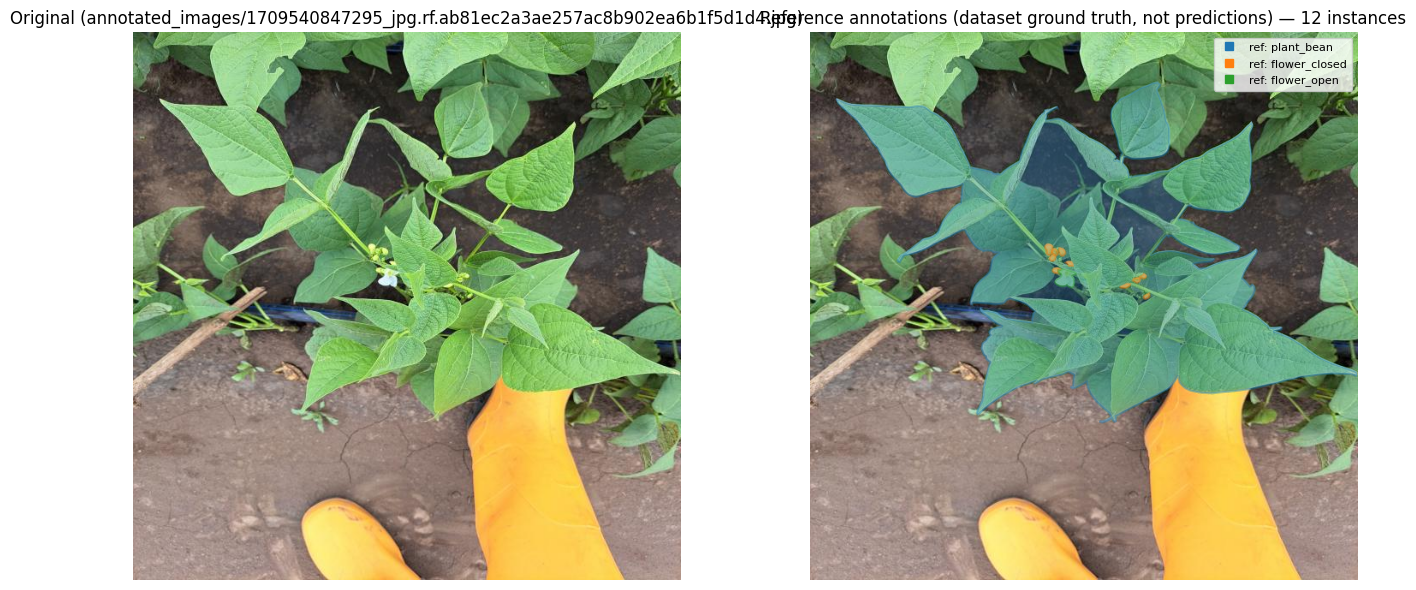

In [ ]:
import numpy as np
from matplotlib.patches import Polygon, Rectangle
from matplotlib import cm

cat_colors = {cid: cm.tab10(i % 10) for i, cid in enumerate(sorted(cats))}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(sel_img)
axes[0].set_title("Original (annotated_images/" + sel_fn + ")")
axes[0].axis("off")

axes[1].imshow(sel_img)
for ann in sel_annotations:
    color = cat_colors[ann["category_id"]]
    segs = ann.get("segmentation") or []
    drew = False
    for seg in segs:
        if isinstance(seg, dict):  # RLE
            continue
        pts = np.array(seg, dtype=float).reshape(-1, 2)
        if len(pts) >= 3:
            axes[1].add_patch(Polygon(pts, closed=True, fill=True,
                                      facecolor=color, alpha=0.35, edgecolor=color, lw=1.5))
            drew = True
    if not drew and ann.get("bbox"):
        x, y, w, h = ann["bbox"]
        axes[1].add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=color, lw=1.5))
        drew = True
    if not drew:
        print("annotation without polygon/bbox:", ann.get("id"))
for cid in {a["category_id"] for a in sel_annotations}:
    axes[1].plot([], [], "s", color=cat_colors[cid], label=f"ref: {cats[cid]}")
axes[1].set_title(f"Reference annotations (dataset ground truth, not predictions) — {len(sel_annotations)} instances")
axes[1].legend(loc="upper right", fontsize=8)
axes[1].axis("off")
plt.tight_layout()
plt.show()

## Artemis metadata: inspect and join

Artemis metadata ships as Parquet and CSV under `Artemis/common-bean/metadata/` (per `docs/artemis.md`: plot identifiers, variety identifiers, treatments, growth stage, and quantitative field observations). The exact schema was not retrievable on the host (the variable dictionary is a data file under our retrieval rules), so the next cell **lists** the metadata subtree and picks the smallest CSV/Parquet file to keep the download small.

**Expected result:** the metadata key listing (a ~37 MB Parquet and a much larger CSV) and the chosen smallest file.

**Expected result (JA):** メタデータサブツリーの一覧を取得し、最小の Parquet（約 37 MB）を選びます。

In [ ]:
meta_prefix = "Artemis/common-bean/metadata/"
meta_keys, token = [], None
while True:
    kw = dict(Bucket=BUCKET, Prefix=meta_prefix, MaxKeys=1000)
    if token:
        kw["ContinuationToken"] = token
    r = s3.list_objects_v2(**kw)
    meta_keys += [(i["Key"], i["Size"]) for i in r.get("Contents", [])
                  if i["Key"].lower().endswith((".csv", ".parquet"))]
    token = r.get("NextContinuationToken")
    if not token:
        break
meta_keys.sort(key=lambda kv: kv[1])
for k, s in meta_keys:
    print(f"{s:>12,}  {k}")
meta_key, meta_size = meta_keys[0]
print("chosen:", meta_key)

  37,364,855  Artemis/common-bean/metadata/common-bean_metadata.parquet
 328,936,891  Artemis/common-bean/metadata/common-bean_metadata.csv
chosen: Artemis/common-bean/metadata/common-bean_metadata.parquet


### Load the chosen metadata file and inspect its schema

Download the chosen metadata file to `/content`, load it with pandas (CSV or Parquet), and print its shape, column names, and dtypes. Column meanings beyond what the data itself shows are defined in the authors' `docs/variable_dictionary.csv`, which is not reproduced here.

**Expected result:** about 1.27 million rows × 24 columns with Artemis field-metadata columns (`crop`, `site`, `country`, `growth_stage`, `plot_id`, `variety_id`, `treatment`, `viewpoint`, `object_key`, ...).

**Expected result (JA):** 選んだメタデータファイルを `/content` にダウンロードして pandas で読み込み、形状・列名・型を表示します。

In [ ]:
meta_body = s3.get_object(Bucket=BUCKET, Key=meta_key)["Body"].read()
assert len(meta_body) == meta_size
print(f"downloaded {meta_key}: {len(meta_body):,} bytes")
local_meta = "/content/" + meta_key.split("/")[-1]
with open(local_meta, "wb") as f:
    f.write(meta_body)

if local_meta.lower().endswith(".csv"):
    meta = pandas.read_csv(local_meta)
else:
    meta = pandas.read_parquet(local_meta)
print("shape:", meta.shape)
print("columns:", list(meta.columns))
print(meta.dtypes)

downloaded Artemis/common-bean/metadata/common-bean_metadata.parquet: 37,364,855 bytes


shape: (1267786, 24)
columns: ['crop', 'site', 'date_captured', 'latitude', 'longitude', 'growth_stage', 'country', 'capture_platform', 'viewpoint', 'spatial_framing', 'viewpoint_framing', 'capture_method', 'capture_angle', 'plot_id', 'variety_id', 'treatment', 'annotation_track', 'annotation_type', 'file_format', 'object_key', 'groundtruth_level', 'groundtruth_trait', 'groundtruth_value', 'has_groundtruth']
crop                         object
site                         object
date_captured                object
latitude                     object
longitude                    object
growth_stage                 object
country                      object
capture_platform             object
viewpoint                    object
spatial_framing              object
viewpoint_framing            object
capture_method               object
capture_angle                object
plot_id                      object
variety_id                   object
treatment                    object
annotation_t

### Join the annotated images to field metadata

The COCO `s3_key` values point at the annotation-set copies, not the original images, so a direct join fails. Instead we recover each annotated image's **original stem** — the roboflow-style name `1709540847295_jpg.rf.<hash>.jpg` embeds the original `1709540847295` — and match it to the basename stem of the metadata `object_key`. We report the actual match rate for all 854 annotated images and show the joined row for the displayed sample. If the mapping matched nothing, the cell fails loudly rather than inventing a link.

**Expected result:** the matched fraction (observed ≈ 53% in diagnostics — not every annotated image has a metadata row under this mapping), and a joined row with plot/variety/growth-stage fields for the sample.

**Expected result (JA):** アノテーション画像名から元画像の stem を復元し、メタデータ `object_key` の stem と結合します。一致率（診断では約 53%）とサンプルの結合行を表示します。

In [ ]:
import os

def orig_stem(file_name):
    return os.path.splitext(file_name)[0].split("_jpg.rf.")[0]

coco_df = pandas.DataFrame([{"file_name": im["file_name"], "_stem": orig_stem(im["file_name"])}
                            for im in coco["images"]])
meta_keyed = meta.copy()
meta_keyed["_stem"] = (meta_keyed["object_key"].astype(str)
                       .map(lambda v: os.path.splitext(os.path.basename(v))[0]))
joined = coco_df.merge(meta_keyed.drop_duplicates("_stem"), on="_stem", how="left")
n_matched = int(joined["object_key"].notna().sum())
match_rate = n_matched / len(joined)
print(f"annotated images joined to metadata: {n_matched}/{len(joined)} ({match_rate:.1%})")
assert n_matched > 0, "no annotated image matched metadata object_key stems"

sample_row = joined[joined["file_name"] == sel_fn]
sample_row[[c for c in ["file_name", "crop", "site", "date_captured", "country",
                        "growth_stage", "plot_id", "variety_id", "treatment",
                        "viewpoint", "capture_platform", "object_key"] if c in sample_row.columns]]

annotated images joined to metadata: 453/854 (53.0%)


,file_name,crop,site,date_captured,country,growth_stage,plot_id,variety_id,treatment,viewpoint,capture_platform,object_key
0,1709540847295_jpg.rf.ab81ec2a3ae257ac8b902ea6b...,Common bean,Arusha--CIAT,2024-03-04,Tanzania,flowering,PLOT101,None,None,above-canopy,handheld,Artemis/common-bean/images/ciat-arusha/artemis...


## Interpretation and limitations

**What was verified here (one example):**
- The public bucket is anonymously browsable; the Image Safari crop prefixes, one potato image, and the authors' crop-distribution reference data were reproduced from the pinned tutorial.
- The Artemis common-bean `flower` instance-segmentation COCO was downloaded with recorded size/SHA-256, and its image/annotation counts matched the authors' documentation (854 / 14,434).
- One deterministically chosen annotated image was overlaid with its **reference annotations** (dataset ground truth, not model output), and the annotated images were joined to Artemis field metadata via original-stem mapping (observed match rate above; the unmatched remainder have no metadata row under this mapping — consistent with the authors' note that sidecar coverage is not 100%).

**Findings worth noting:** the bucket's actual annotation layout (`annotations/bush-bean/<task>/<set>/`) differs from the pinned docs' `annotations/standard/...` description, and flower-set images are 640×640 roboflow-preprocessed copies rather than original Artemis JPEGs.

**Limitations:** this is a single-example walkthrough of a ~7.5-million-image collection — no dataset-level statistics were recomputed, no benchmark was run, and the paper's full text was unavailable (publisher 403), so all scientific provenance comes from the authors' documentation and code at pinned commit `05868dd`, not from the paper body. Per the authors' README, ~11% of Image Safari images lack metadata sidecars but remain valid; Artemis metadata provenance is described in their variable dictionary. A one-example count match is a plausibility check, not a quantitative verification of the whole dataset.

**要点:** 本ノートブックは大規模コレクションの 1 例を扱うデモであり、データセット全体の統計再計算やベンチマークは行っていません。バケットの実際の配置はドキュメント記述と一部異なります。論文本文は取得不可のため、根拠は pinned コミットの著者ドキュメント・コードと公開 S3 です。

### Small results summary and CSV export

Export the verification results as a small CSV in the Colab VM (`/content`) for reuse: the verified counts, the sample image, and the metadata match rate.

**Expected result:** a one-row summary DataFrame displayed and written to `/content/artemis_flower_verification.csv`.

**Expected result (JA):** 検証結果の要約 1 行を `/content/artemis_flower_verification.csv` に保存して表示します。

In [ ]:
summary = pandas.DataFrame([{
    "paper_doi": "10.31220/agriRxiv.2026.00491",
    "author_repo_commit": "05868dd7071f8d366ab64373ea87afe24b8150e4",
    "artemis_set": json_key,
    "coco_sha256": sha256,
    "images": n_images,
    "annotations": n_anns,
    "doc_images": DOC_IMAGES,
    "doc_annotations": DOC_ANNOTATIONS,
    "counts_match_docs": bool(n_images == DOC_IMAGES and n_anns == DOC_ANNOTATIONS),
    "sample_image": sel_fn,
    "sample_annotations": len(sel_annotations),
    "metadata_file": meta_key,
    "annotated_images_metadata_matched": n_matched,
    "annotated_images_total": len(joined),
    "annotated_images_metadata_match_rate": round(match_rate, 4),
}])
summary.to_csv("/content/artemis_flower_verification.csv", index=False)
summary

,paper_doi,author_repo_commit,artemis_set,coco_sha256,images,annotations,doc_images,doc_annotations,counts_match_docs,sample_image,sample_annotations,metadata_file,annotated_images_metadata_matched,annotated_images_total,annotated_images_metadata_match_rate
0,10.31220/agriRxiv.2026.00491,05868dd7071f8d366ab64373ea87afe24b8150e4,Artemis/common-bean/annotations/bush-bean/inst...,386548c8c7ce5bd841f06ef248d860ec4cedc122c7b374...,854,14434,854,14434,True,1709540847295_jpg.rf.ab81ec2a3ae257ac8b902ea6b...,12,Artemis/common-bean/metadata/common-bean_metad...,453,854,0.5304


## License and citation

The Artemis and Image Safari collection is released under the [Creative Commons Attribution-ShareAlike 4.0 International License](https://creativecommons.org/licenses/by-sa/4.0/). Adapted material must be distributed under the same license.

> Mutuvi S. et al. (2026). *Artemis and Image Safari - Crop Imagery Datasets Spanning Globally Critical Crop Species.* https://doi.org/10.31220/agriRxiv.2026.00491

When accessing data through AWS, also cite the registry entry ([registry.opendata.aws/artemis-image-safari](https://registry.opendata.aws/artemis-image-safari)) with the access date and release version. The full author list is in the repository's `CITATION.cff`. Tutorial code cells in this notebook are copied from the authors' pinned tutorial commit `05868dd7071f8d366ab64373ea87afe24b8150e4`; Artemis verification cells are new code written for this reproduction.